<a href="https://colab.research.google.com/github/Ashwini9713/fundamentals-of-ML/blob/main/exp_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Converged at iteration 22
Means  : [1.871 7.035]
Std dev: [0.902 1.582]
Weights: [0.489 0.511]


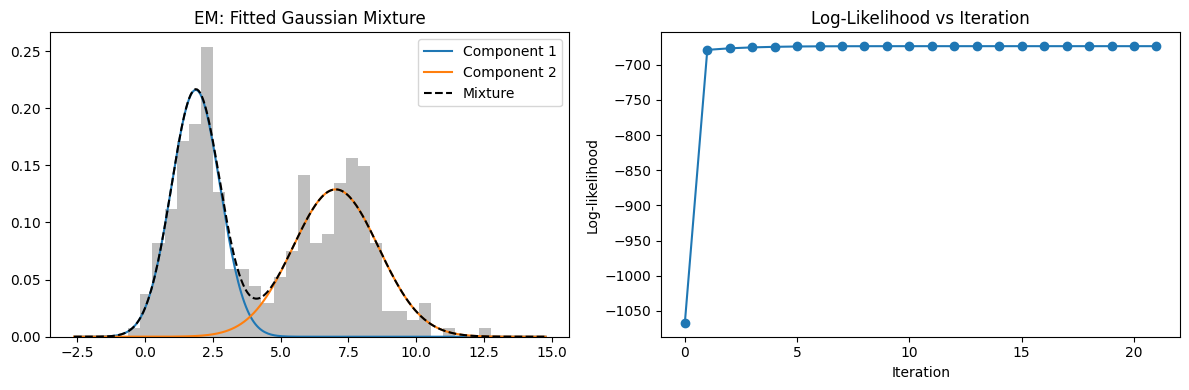

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# 1. Generate data from 2 Gaussians
np.random.seed(42)
data = np.concatenate([np.random.normal(2, 1.0, 150),
                       np.random.normal(7, 1.5, 150)])

# 2. Initialize parameters
K = 2
mu = np.array([1.0, 5.0])
sigma = np.array([1.0, 1.0])
pi = np.array([0.5, 0.5])

log_likelihoods = []
for it in range(100):
    # E-step: responsibilities
    resp = np.array([pi[k] * norm.pdf(data, mu[k], sigma[k]) for k in range(K)])
    ll = np.sum(np.log(resp.sum(axis=0)))
    resp /= resp.sum(axis=0)

    # M-step: update parameters
    Nk = resp.sum(axis=1)
    mu = (resp * data).sum(axis=1) / Nk
    sigma = np.sqrt((resp * (data - mu[:, None])**2).sum(axis=1) / Nk)
    pi = Nk / len(data)

    log_likelihoods.append(ll)
    if it > 0 and abs(ll - log_likelihoods[-2]) < 1e-6:
        print(f"Converged at iteration {it + 1}")
        break

print("Means  :", mu.round(3))
print("Std dev:", sigma.round(3))
print("Weights:", pi.round(3))

# 3. Plots
x = np.linspace(data.min() - 2, data.max() + 2, 300)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(data, bins=30, density=True, alpha=0.5, color="gray")
for k in range(K):
    ax[0].plot(x, pi[k] * norm.pdf(x, mu[k], sigma[k]), label=f"Component {k+1}")
ax[0].plot(x, sum(pi[k] * norm.pdf(x, mu[k], sigma[k]) for k in range(K)), "k--", label="Mixture")
ax[0].set_title("EM: Fitted Gaussian Mixture"); ax[0].legend()
ax[1].plot(log_likelihoods, marker="o")
ax[1].set_title("Log-Likelihood vs Iteration")
ax[1].set_xlabel("Iteration"); ax[1].set_ylabel("Log-likelihood")
plt.tight_layout()
plt.show()